# Captive RE siting around industrial facilities

This notebook runs the captive-RE siting workflow end to end at demo scale: 10-km buffers
around industrial facilities, land-cover suitability inside each buffer, ERA5 capacity-factor
surfaces, and the per-facility potential table that feeds GARUDA. Two stand-ins keep it small:
the three facilities below **stand in for the real captive facility CSV**, and **one month of
weather (January 2023 over the NTT box) stands in for the full analysis year**. Every step is
written so the real inputs drop in without structural changes — the closing section lists the
exact one-line deltas.

In [1]:
import logging
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import shapely
import xarray as xr
from shapely.geometry import box

import garudata as gd
from garudata.profiles import indonesia as idn

logging.basicConfig(level=logging.WARNING)  # keep garudata's INFO chatter out of the outputs
# rasterio 1.5 reads trip a harmless NumPy 2.5 deprecation about in-place .shape
warnings.filterwarnings("ignore", message="Setting the shape on a NumPy array")

STORE = "../validation/store"               # ERA5 store: 2023-01 over the NTT box
LAND_TIF = "../landcover_suitability.tif"   # suitability scores {0, 2, 3}, full Indonesia
RES_DEG = 0.01                              # fine suitability grid (~1.1 km)
W, S, E, N = idn.BBOX_NTT
OUT = Path("_out/nb03")
OUT.mkdir(parents=True, exist_ok=True)

## 1. Demo facilities and their 10-km buffers

Three demo sites — two in the Kupang industrial area, one near Atambua.
`gd.siting.facility_buffers` buffers the points by `idn.FACILITY_BUFFER_KM` (10 km) in
equal-area EPSG:6933 and returns a plain `{name: polygon}` dict in lon/lat — the shape
dict every later step consumes.

In [2]:
facilities = pd.DataFrame(
    {
        "Facility": ["semen_kupang", "bolok_industrial_estate", "atambua_site"],
        "Latitude": [-10.171, -10.184, -9.106],
        "Longitude": [123.723, 123.486, 124.892],
    }
)
buffers = gd.siting.facility_buffers(facilities, radius_km=idn.FACILITY_BUFFER_KM)
facilities

,Facility,Latitude,Longitude
0,semen_kupang,-10.171,123.723
1,bolok_industrial_estate,-10.184,123.486
2,atambua_site,-9.106,124.892


A windowed read of the national suitability raster (no full-raster load) gives a quick
map of where the buffers sit relative to suitable land — note how much of the coastal
Bolok buffer falls over the sea (score 0).

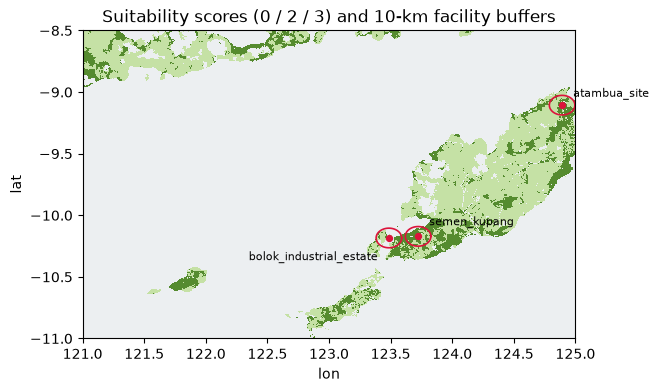

In [3]:
# Coarse background: windowed read of the suitability raster over the NTT box
# (the NTT window is ~1500 x 870 px of the 10000 x 10000 national raster).
from matplotlib.colors import BoundaryNorm, ListedColormap

with rasterio.open(LAND_TIF) as src:
    win = rasterio.windows.from_bounds(W, S, E, N, src.transform)
    bg = src.read(1, window=win)

cmap = ListedColormap(["#eceff1", "#c5e1a5", "#558b2f"])  # 0 unsuitable, 2 incl. shrub/savanna, 3 strict
norm = BoundaryNorm([-0.5, 1.0, 2.5, 3.5], cmap.N)

fig, ax = plt.subplots(figsize=(9, 4))
ax.imshow(bg, extent=(W, E, S, N), cmap=cmap, norm=norm, interpolation="nearest")
for poly in buffers.values():
    bx, by = poly.exterior.xy
    ax.plot(bx, by, color="crimson", lw=1.2)
ax.scatter(facilities["Longitude"], facilities["Latitude"], color="crimson", s=18, zorder=3)
label_at = {"semen_kupang": (8, 8, "left"),
            "bolok_industrial_estate": (-8, -16, "right"),
            "atambua_site": (8, 6, "left")}
for _, r in facilities.iterrows():
    dx, dy, ha = label_at[r["Facility"]]
    ax.annotate(r["Facility"], (r["Longitude"], r["Latitude"]),
                textcoords="offset points", xytext=(dx, dy), ha=ha, fontsize=8)
ax.set(xlabel="lon", ylabel="lat",
       title="Suitability scores (0 / 2 / 3) and 10-km facility buffers");

## 2. Land suitability on a 0.01° grid

Notebook 02 saves this grid; if its output is present we reuse it, otherwise we recompute
inline with `gd.land.suitable_area_by_cell` (windowed, native-CRS, ~2 s here) so this
notebook stands alone. `fraction` is suitable area divided by the geometric (cos-lat) cell
area; `block=2` keeps the sample spacing below the 0.01° cell size.

**Where the slope exclusion plugs in:** the full captive run passes
`exclusion_samplers=[gd.land.terrain_sampler(SLOPE_TIF, idn.SLOPE_MAX_SOLAR_PCT)]` here
(5 **percent** for solar, `idn.SLOPE_MAX_WIND_PCT` = 20 for wind — the thresholds are percent,
not degrees), which yields *separate* solar and wind suitability grids. No slope raster ships
with this repo, so the demo skips it and one grid serves both technologies.

In [4]:
suit_nc = Path("_out/nb02/suitability_ntt_001deg.nc")  # produced by notebook 02
if suit_nc.exists():
    suit_ds = xr.load_dataset(suit_nc)
    print(f"reusing {suit_nc}")
else:
    lons = np.arange(W + RES_DEG / 2, E, RES_DEG)
    lats = np.arange(S + RES_DEG / 2, N, RES_DEG)
    suit_ds = gd.land.suitable_area_by_cell(LAND_TIF, idn.SUITABLE_SCORES, lons, lats, block=2)
    print("notebook 02 output not found - recomputed inline")

suit = suit_ds["fraction"] if "fraction" in suit_ds else suit_ds[next(iter(suit_ds.data_vars))]
lats_v, lons_v = suit["lat"].values, suit["lon"].values

# geometric cell areas (cos-lat, 111.32 km/deg) -> per-cell suitable km2
cell_km2 = xr.DataArray(
    np.outer((RES_DEG * 111.32) * (RES_DEG * 111.32) * np.cos(np.deg2rad(lats_v)),
             np.ones(lons_v.size)),
    coords={"lat": lats_v, "lon": lons_v}, dims=("lat", "lon"),
)
suit_km2 = suit * cell_km2
print(f"grid {suit.sizes['lat']} x {suit.sizes['lon']} | "
      f"suitable area {float(suit_km2.sum()):,.0f} km2 "
      f"({float(suit.mean()):.1%} of the box)")

reusing _out/nb02/suitability_ntt_001deg.nc


grid 250 x 400 | suitable area 19,050 km2 (15.6% of the box)


## 3. Capacity-factor surfaces from the January-2023 store

`Cutout` is a lazy view over the monthly store (no copies); `.canonical()` applies the
raw-CDS → canonical translation (J m⁻² → W m⁻², `wnd100m`, …). We take monthly means of the
GHI-model solar CF and the Siemens SWT-107 wind CF — the box means (solar 0.186, wind 0.202)
match the validated reference run in `validation/REPORT_2023-01_ntt.md`.

744 hours on a 11 x 17 ERA5 grid | box-mean CF: solar 0.186, wind 0.202


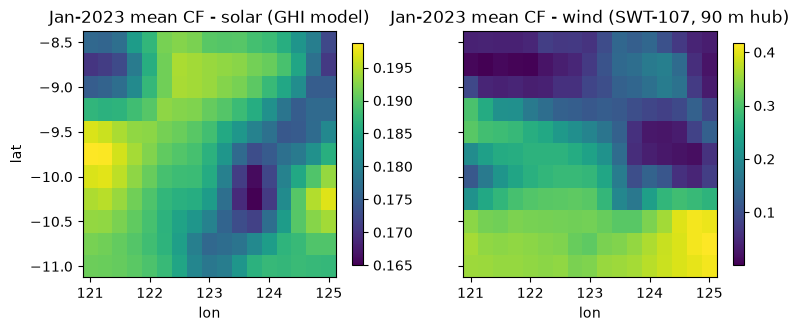

In [5]:
cut = gd.cutout.Cutout(config="wind_solar_hourly", years=[2023], months=[1],
                       bounds_wsen=idn.BBOX_NTT, store_root=STORE)
ds = cut.canonical()
solar_cf = gd.convert.pv_cf_ghi(ds).mean("time")
wind_cf = gd.convert.wind_cf(ds, turbine=idn.TURBINE).mean("time")
print(f"{ds.sizes['time']} hours on a {ds.sizes['y']} x {ds.sizes['x']} ERA5 grid | "
      f"box-mean CF: solar {float(solar_cf.mean()):.3f}, wind {float(wind_cf.mean()):.3f}")

fig, axs = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, cf, label in ((axs[0], solar_cf, "solar (GHI model)"),
                      (axs[1], wind_cf, "wind (SWT-107, 90 m hub)")):
    im = ax.pcolormesh(cf["x"], cf["y"], cf, cmap="viridis", shading="nearest")
    fig.colorbar(im, ax=ax, shrink=0.9)
    ax.set(xlabel="lon", title=f"Jan-2023 mean CF - {label}")
axs[0].set(ylabel="lat");

## 4. Per-facility potential and the GARUDA artifact

`gd.siting.facility_potential` clips the fine suitability grid to each buffer, sums suitable
area with cos-lat cell weights, nearest-upsamples the coarse CF surface onto the clip and
averages it over suitable cells, then converts area to capacity with the packing density
(`idn.PACKING`: solar 30 MW/km², wind 3.9 MW/km²).

In [6]:
solar_pot = gd.siting.facility_potential(
    suit, solar_cf, buffers, packing_mw_per_km2=idn.PACKING["captive_solar"])
wind_pot = gd.siting.facility_potential(
    suit, wind_cf, buffers, packing_mw_per_km2=idn.PACKING["captive_wind"])
solar_pot

,Facility,suitable_area_km2,mean_CF,capacity_MW,flagged
0,atambua_site,307.970675,0.175315,9239.120248,False
1,bolok_industrial_estate,164.257721,0.169072,4927.731643,False
2,semen_kupang,279.553724,0.165124,8386.611715,False


The wind table shares the same suitable-area column (land does not change with
technology) but swaps in the wind CF surface and the much sparser wind packing density.

In [7]:
wind_pot

,Facility,suitable_area_km2,mean_CF,capacity_MW,flagged
0,bolok_industrial_estate,164.257721,0.192733,640.605114,False
1,semen_kupang,279.553724,0.157974,1090.259523,False
2,atambua_site,307.970675,0.063906,1201.085632,False


`write_captive_potential` merges the two tables into the single per-facility CSV that
GARUDA consumes.

In [8]:
csv_path = gd.writers.write_captive_potential(solar_pot, wind_pot, 2023, str(OUT))
pd.read_csv(csv_path)

,Facility,suitable_area_km2,solar_CF,solar_MW,wind_CF,wind_MW
0,atambua_site,307.970675,0.175315,9239.120248,0.063906,1201.085632
1,bolok_industrial_estate,164.257721,0.169072,4927.731643,0.192733,640.605114
2,semen_kupang,279.553724,0.165124,8386.611715,0.157974,1090.259523


The merged CSV (`captive_potential_<year>.csv`, the exact schema GARUDA consumes) reads as:

- **`Facility`** — buffer key from `facility_buffers` (the facility CSV's name column);
- **`suitable_area_km2`** — score ≥ 2 land inside the 10-km buffer (a full buffer is
  π·10² ≈ 314 km²; `bolok_industrial_estate` is coastal, so much of its buffer is sea);
- **`solar_CF` / `wind_CF`** — mean of the ERA5 CF surface over the buffer's *suitable* cells
  (here a January mean; an annual mean in the real run);
- **`solar_MW` / `wind_MW`** — `suitable_area_km2` × packing density.

Rows keep the solar table's order (mean CF descending); the internal `flagged` diagnostic
column is dropped by the writer.

## 5. Downstream extras: land allocation and grid distance

Two more GARUDA plug-points. First, `gd.siting.allocate_to_points` distributes a
polygon-level quantity (here: MW on high-suitability land) to sites. We polygonize the cells
with suitability ≥ 0.8 within 15 km of a facility and allocate with a 15-km radius — chosen
so the corridor between the two Kupang-area sites (~26 km apart) is within reach of *both*,
which exercises the equal-split rule of `shared` mode. All three modes are run for
comparison.

In [9]:
roi = gd.siting.facility_buffers(facilities, radius_km=15.0)
lon_g, lat_g = np.meshgrid(lons_v, lats_v)
in_roi = np.zeros(lon_g.shape, bool)
for poly in roi.values():
    in_roi |= shapely.contains_xy(poly, lon_g, lat_g)
sel = in_roi & (suit.values >= 0.8)

iy, ix = np.nonzero(sel)
cells = gpd.GeoDataFrame(
    {"cap_mw": suit_km2.values[sel] * idn.PACKING["captive_solar"]},
    geometry=[box(x - RES_DEG / 2, y - RES_DEG / 2, x + RES_DEG / 2, y + RES_DEG / 2)
              for x, y in zip(lons_v[ix], lats_v[iy])],
    crs="EPSG:4326",
)
print(f"{len(cells)} high-suitability cells, {cells.cap_mw.sum():,.0f} MW at solar packing")

alloc = {mode: gd.siting.allocate_to_points(cells, facilities, value_col="cap_mw",
                                            mode=mode, radius_km=15.0)
         for mode in ("shared", "buffer", "nearest")}
comp = pd.DataFrame({m: a["cap_mw"].to_numpy() for m, a in alloc.items()},
                    index=facilities["Facility"])
comp.loc["TOTAL allocated"] = comp.sum()
comp.loc["land that exists"] = cells.cap_mw.sum()
comp.round(0)

995 high-suitability cells, 36,998 MW at solar packing


,shared,buffer,nearest
Facility,,,
semen_kupang,14341.0,15016.0,14320.0
bolok_industrial_estate,7324.0,8129.0,7345.0
atambua_site,15332.0,15259.0,15332.0
TOTAL allocated,36998.0,38403.0,36998.0
land that exists,36998.0,36998.0,36998.0


**Mode trade-offs.** `shared` splits each polygon equally among all sites in range — it
*conserves totals* (TOTAL allocated = land that exists) with no double counting and no
starved site, which is why it is the canonical `usable_land.py` algorithm. `buffer` answers
"what could *this* site develop within R km" — the shared corridor is counted once per site,
so the total *exceeds* the land that exists (on the real Timor layer this inflated 233 GW to
2,472 GW). `nearest` also conserves, but hands each polygon wholly to the marginally closest
site — any site that is never the closest gets exactly zero (178 of 627 Timor villages, in
the run that motivated the shared fix).

Second, `gd.siting.hub_distance` — nearest substation per facility, feeding GARUDA's
connection cost (`hubdist_km`) and `Zone` (the substation name). Two demo substations stand
in for the real grid layer; EPSG:3857 is used for near-true distance scale at the equator
(the equal-area default EPSG:6933 is ±13–15 % anisotropic here).

In [10]:
substations = gpd.GeoDataFrame(
    {"name": ["kupang", "atambua"]},
    geometry=gpd.points_from_xy([123.60, 124.89], [-10.17, -9.10]),
    crs="EPSG:4326",
)
hubs = gd.siting.hub_distance(facilities, substations, metric_crs="EPSG:3857")
pd.concat([facilities, hubs], axis=1)

,Facility,Latitude,Longitude,hubdist_km,hub_name
0,semen_kupang,-10.171,123.723,13.692764,kupang
1,bolok_industrial_estate,-10.184,123.486,12.788820,kupang
2,atambua_site,-9.106,124.892,0.712134,atambua


## 6. From demo to the real captive run

Everything above runs unchanged at national scale — only the inputs change:

- **Domain**: `W, S, E, N = idn.BBOX_INDONESIA` (the fine grid axes and cutout bounds follow).
- **Weather**: a full year of the representative captive year —
  `gd.cutout.Cutout(config="wind_solar_hourly", years=[idn.YEAR_CAPTIVE], bounds_wsen=idn.BBOX_INDONESIA, store_root=...)`
  (months default to all twelve, so the CF means become annual means; if the store has gaps,
  `gd.weather.download_era5_wind_solar(years=[idn.YEAR_CAPTIVE], months=range(1, 13), bounds_wsen=idn.BBOX_INDONESIA)` fills them).
- **Facilities**: `facilities = pd.read_csv("industrial_facilities.csv")` — the real captive
  facility list (name/lat/lon column aliases are auto-detected).
- **Slope**: per-technology suitability grids —
  `gd.land.suitable_area_by_cell(LAND_TIF, idn.SUITABLE_SCORES, lons, lats, exclusion_samplers=[gd.land.terrain_sampler("USGS_slope_indonesia.tif", idn.SLOPE_MAX_SOLAR_PCT)])`
  for solar and the same call with `idn.SLOPE_MAX_WIND_PCT` for wind, each feeding its own
  `facility_potential` pass.
- **Substations**: `substations = gpd.read_file("substations.gpkg")` into the same
  `hub_distance` call.

The buffers, `facility_potential`, the writer and the allocation modes need no edits.